## Dataset Description

In [1]:

# Import the pandas library to load and analyse data
import pandas as pd

# Load the original Kaggle CSV dataset
# encoding="latin1" helps read special characters in the file
df = pd.read_csv(
    r"F:\Projects\OnlineRetail.csv",
    encoding="latin1"
)

# Display a message confirming that the dataset has loaded
print("Dataset loaded successfully!")

# Display the number of rows and columns
# Expected: 6000 rows and 8 columns for the selected Kaggle dataset
print("Dataset size:", df.shape)

# Display the first five rows to understand the dataset structure
display(df.head())


Dataset loaded successfully!
Dataset size: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01-12-2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01-12-2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01-12-2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01-12-2010 08:26,3.39,17850.0,United Kingdom


In [2]:

# Import pandas to work with tabular data
import pandas as pd

# Display the number of rows and columns in the dataset
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display the data types and non-null counts
# This helps us identify columns that may need correction
print("\nDataset information:")
df.info()

# Count missing values in each column
# Missing values may need to be handled during data cleaning
print("\nMissing values in each column:")
print(df.isnull().sum())

# Count duplicate rows
# Duplicate records can affect our analysis
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Display basic statistics for numerical columns
# This helps us understand quantities and prices
print("\nNumerical summary:")
display(df.describe())


Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Numb

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [3]:

# Count transactions with negative quantities
# These may represent returned goods or cancelled transactions
print("Negative quantities:", (df["Quantity"] < 0).sum())

# Count transactions with zero quantity
print("Zero quantities:", (df["Quantity"] == 0).sum())

# Count transactions with negative unit prices
# These require inspection before deciding how to handle them
print("Negative unit prices:", (df["UnitPrice"] < 0).sum())

# Count transactions with zero unit prices
print("Zero unit prices:", (df["UnitPrice"] == 0).sum())

# Invoice numbers beginning with C commonly indicate cancellations
# Convert invoice numbers to strings before checking
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")

print("Invoices marked as cancellations:", cancelled.sum())

# Display examples of negative-quantity transactions
display(df[df["Quantity"] < 0].head(10))

# Display examples of negative-price transactions
display(df[df["UnitPrice"] < 0].head(10))


Negative quantities: 10624
Zero quantities: 0
Negative unit prices: 2
Zero unit prices: 2515
Invoices marked as cancellations: 9288


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,01-12-2010 09:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,01-12-2010 09:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,01-12-2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,01-12-2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,01-12-2010 10:24,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,01-12-2010 10:24,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,01-12-2010 10:24,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,01-12-2010 10:24,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,01-12-2010 10:24,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,01-12-2010 12:38,4.25,17897.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,12-08-2011 14:51,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,12-08-2011 14:52,-11062.06,NaN,United Kingdom


## Data Cleaning

In [4]:

# Import pandas for data manipulation
import pandas as pd

# Create a working copy so the original dataset remains unchanged
clean_df = df.copy()

# Step 1: Remove exact duplicate rows
clean_df = clean_df.drop_duplicates()

# Step 2: Remove rows without a product description
clean_df = clean_df.dropna(subset=["Description"])

# Step 3: Convert InvoiceDate from text to datetime
# Invalid dates, if any, will become missing values
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"],
    dayfirst=True,
    errors="coerce"
)

# Remove rows where the date could not be converted
clean_df = clean_df.dropna(subset=["InvoiceDate"])

# Step 4: Remove cancelled invoices
# Invoice numbers beginning with C indicate cancellations
is_cancelled = clean_df["InvoiceNo"].astype(str).str.startswith("C")
clean_df = clean_df[~is_cancelled]

# Step 5: Keep rows with known customer IDs for the RFM dataset
# We will preserve a separate dataset for broader sales analysis
sales_df = clean_df.copy()

# Step 6: Keep positive quantities and positive prices
# This creates a positive-sales dataset, excluding returns and zero/negative prices
sales_df = sales_df[
    (sales_df["Quantity"] > 0) &
    (sales_df["UnitPrice"] > 0)
].copy()

# Step 7: Create the RFM dataset with known customer IDs
rfm_df = sales_df.dropna(subset=["CustomerID"]).copy()

# Convert CustomerID to integer for easier grouping
rfm_df["CustomerID"] = rfm_df["CustomerID"].astype(int)

# Step 8: Calculate revenue for each transaction line
rfm_df["Revenue"] = rfm_df["Quantity"] * rfm_df["UnitPrice"]

# Display the number of rows remaining after cleaning
print("Original rows:", len(df))
print("Rows after basic cleaning:", len(clean_df))
print("Positive-sales rows:", len(sales_df))
print("Rows available for RFM analysis:", len(rfm_df))

# Confirm that the key columns have no missing values in the RFM dataset
print("\nMissing values in RFM dataset:")
print(rfm_df[[
    "InvoiceNo", "InvoiceDate", "CustomerID",
    "Quantity", "UnitPrice", "Revenue"
]].isnull().sum())

# Display the first five cleaned records
display(rfm_df.head())


Original rows: 541909
Rows after basic cleaning: 525936
Positive-sales rows: 524878
Rows available for RFM analysis: 392692

Missing values in RFM dataset:
InvoiceNo      0
InvoiceDate    0
CustomerID     0
Quantity       0
UnitPrice      0
Revenue        0
dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


## Exploratory Data Analysis

In [5]:

# Count the number of unique customers in the RFM dataset
total_customers = rfm_df["CustomerID"].nunique()

# Count the number of unique products
total_products = rfm_df["StockCode"].nunique()

# Count unique invoices as a measure of purchase transactions
total_invoices = rfm_df["InvoiceNo"].nunique()

# Calculate total revenue from positive sales records
total_revenue = rfm_df["Revenue"].sum()

# Calculate the average revenue per transaction line
average_line_revenue = rfm_df["Revenue"].mean()

# Display the key business metrics
print("Total unique customers:", total_customers)
print("Total unique products:", total_products)
print("Total unique invoices:", total_invoices)
print("Total revenue: £{:,.2f}".format(total_revenue))
print("Average revenue per transaction line: £{:.2f}".format(average_line_revenue))


Total unique customers: 4338
Total unique products: 3665
Total unique invoices: 18532
Total revenue: £8,887,208.89
Average revenue per transaction line: £22.63


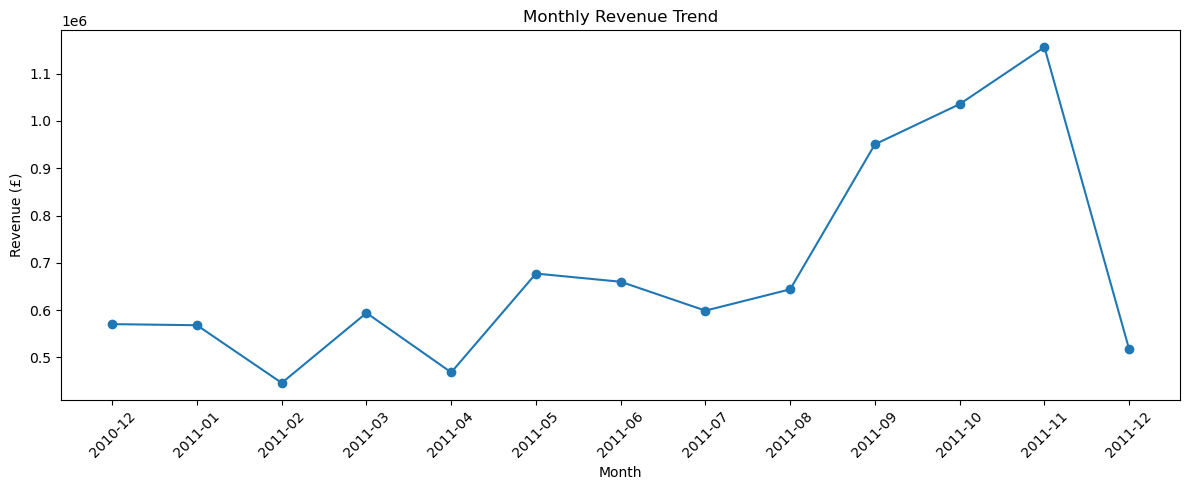

In [6]:

# Group the cleaned RFM data by month and add up revenue
monthly_revenue = (
    rfm_df.groupby(rfm_df["InvoiceDate"].dt.to_period("M"))["Revenue"]
    .sum()
)

# Create a line chart of monthly revenue
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

# Add the chart title and axis labels
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")

# Rotate the month labels for readability
plt.xticks(rotation=45)

# Display the chart neatly
plt.tight_layout()
plt.show()


Top 10 Products by Revenue:


,Description,Revenue
0,"PAPER CRAFT , LITTLE BIRDIE",168469.60
1,REGENCY CAKESTAND 3 TIER,142264.75
2,WHITE HANGING HEART T-LIGHT HOLDER,100392.10
3,JUMBO BAG RED RETROSPOT,85040.54
4,MEDIUM CERAMIC TOP STORAGE JAR,81416.73
5,POSTAGE,77803.96
6,PARTY BUNTING,68785.23
7,ASSORTED COLOUR BIRD ORNAMENT,56413.03
8,Manual,53419.93
9,RABBIT NIGHT LIGHT,51251.24


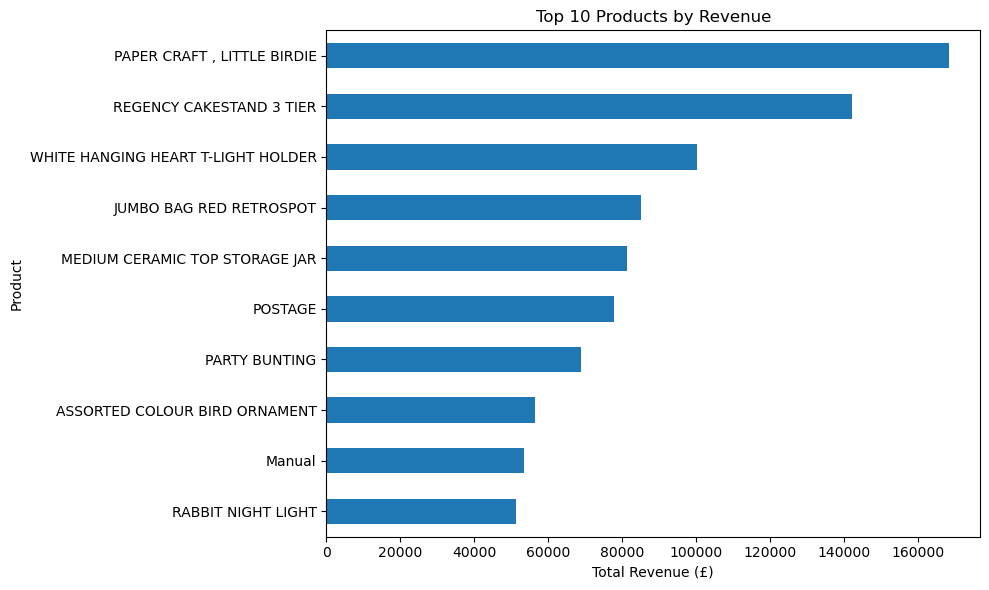

In [7]:
# Group sales by product description and calculate total revenue
top_products = (
    rfm_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Display the top 10 products and their total revenue
print("Top 10 Products by Revenue:")
display(top_products.reset_index())

# Import the plotting library
import matplotlib.pyplot as plt

# Create a horizontal bar chart of the top 10 products
plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind="barh")

# Add a title and axis labels
plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Product")

# Adjust spacing and display the chart
plt.tight_layout()
plt.show()

Top 10 Countries by Revenue:


,Country,Revenue
0,United Kingdom,7285024.644
1,Netherlands,285446.340
2,EIRE,265262.460
3,Germany,228678.400
4,France,208934.310
5,Australia,138453.810
6,Spain,61558.560
7,Switzerland,56443.950
8,Belgium,41196.340
9,Sweden,38367.830


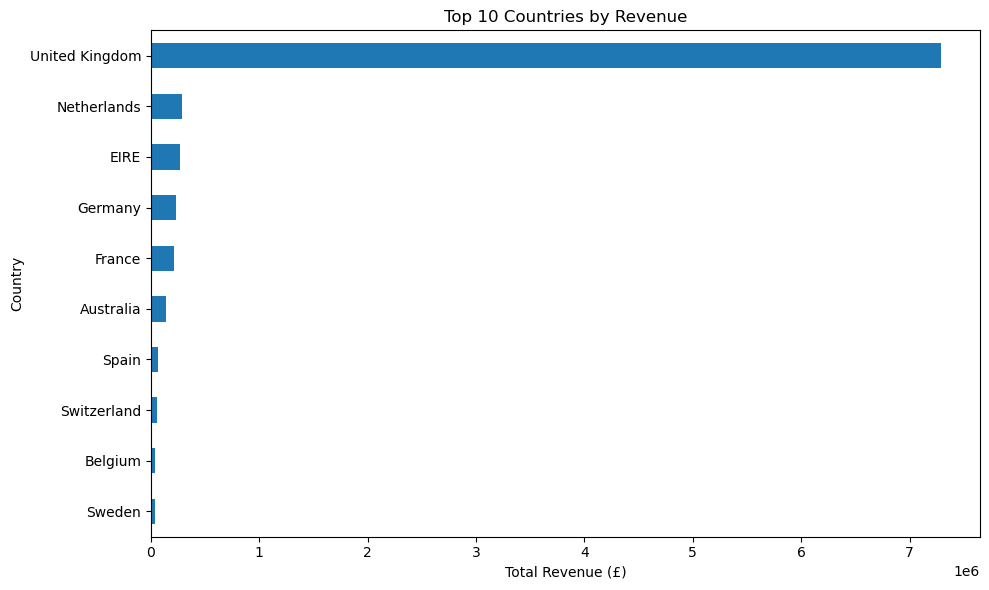

In [8]:
# Group sales by country and calculate total revenue
top_countries = (
    rfm_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Display the top 10 countries by revenue
print("Top 10 Countries by Revenue:")
display(top_countries.reset_index())

# Import the plotting library
import matplotlib.pyplot as plt

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))
top_countries.sort_values().plot(kind="barh")

# Add the chart title and axis labels
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Country")

# Display the chart neatly
plt.tight_layout()
plt.show()

In [9]:
# Import pandas for data analysis
import pandas as pd

# Set the reference date to one day after the latest transaction
# This makes recency easier to calculate
reference_date = rfm_df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Group transaction records by customer and calculate RFM values
rfm = rfm_df.groupby("CustomerID").agg(
    # Find each customer's most recent purchase date
    LastPurchaseDate=("InvoiceDate", "max"),

    # Count the number of unique invoices for each customer
    Frequency=("InvoiceNo", "nunique"),

    # Add up the revenue generated by each customer
    Monetary=("Revenue", "sum")
).reset_index()

# Calculate recency in days
rfm["Recency"] = (
    reference_date - rfm["LastPurchaseDate"]
).dt.days

# Display the first five customers and their RFM values
display(rfm.head())

# Display the total number of customers analysed
print("Total customers analysed:", len(rfm))

,CustomerID,LastPurchaseDate,Frequency,Monetary,Recency
0,12346,2011-01-18 10:01:00,1,77183.60,326
1,12347,2011-12-07 15:52:00,7,4310.00,2
2,12348,2011-09-25 13:13:00,4,1797.24,75
3,12349,2011-11-21 09:51:00,1,1757.55,19
4,12350,2011-02-02 16:01:00,1,334.40,310


Total customers analysed: 4338


## RFM Analysis

In [10]:
# Assign Recency scores: more recent purchases receive higher scores
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Assign Frequency scores: customers with more invoices receive higher scores
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Assign Monetary scores: customers who spend more receive higher scores
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine the three scores into one RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

# Display the scores for the first five customers
display(
    rfm[
        ["CustomerID", "Recency", "Frequency", "Monetary",
         "R_Score", "F_Score", "M_Score", "RFM_Score"]
    ].head()
)

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,1,77183.60,1,1,5,115
1,12347,2,7,4310.00,5,5,5,555
2,12348,75,4,1797.24,2,4,4,244
3,12349,19,1,1757.55,4,1,4,414
4,12350,310,1,334.40,1,1,2,112


In [11]:
# Create a function to classify customers using their RFM scores
def assign_segment(row):

    # Customers with high scores in all three areas are Champions
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "Champions"

    # Customers who purchase frequently are classified as Loyal
    elif row["F_Score"] >= 4 and row["R_Score"] >= 3:
        return "Loyal Customers"

    # Recent customers who purchase infrequently may become loyal
    elif row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "Recent Customers"

    # Previously frequent customers who have not purchased recently
    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At Risk"

    # Customers with low recency and frequency scores need attention
    elif row["R_Score"] <= 2 and row["F_Score"] <= 2:
        return "Needs Attention"

    # Remaining customers may become loyal with suitable offers
    else:
        return "Potential Loyalists"


# Apply the function to every customer
rfm["Segment"] = rfm.apply(assign_segment, axis=1)

# Display a sample of customer segments
display(
    rfm[
        ["CustomerID", "R_Score", "F_Score", "M_Score",
         "RFM_Score", "Segment"]
    ].head(10)
)

# Count the customers in each segment
print("Number of customers in each segment:")
display(rfm["Segment"].value_counts().reset_index(name="Customer Count"))


,CustomerID,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,1,1,5,115,Needs Attention
1,12347,5,5,5,555,Champions
2,12348,2,4,4,244,At Risk
3,12349,4,1,4,414,Recent Customers
4,12350,1,1,2,112,Needs Attention
5,12352,3,5,5,355,Loyal Customers
6,12353,1,1,1,111,Needs Attention
7,12354,1,1,4,114,Needs Attention
8,12355,1,1,2,112,Needs Attention
9,12356,4,3,5,435,Potential Loyalists


Number of customers in each segment:


,Segment,Customer Count
0,Needs Attention,1074
1,Champions,942
2,Potential Loyalists,843
3,At Risk,661
4,Loyal Customers,508
5,Recent Customers,310


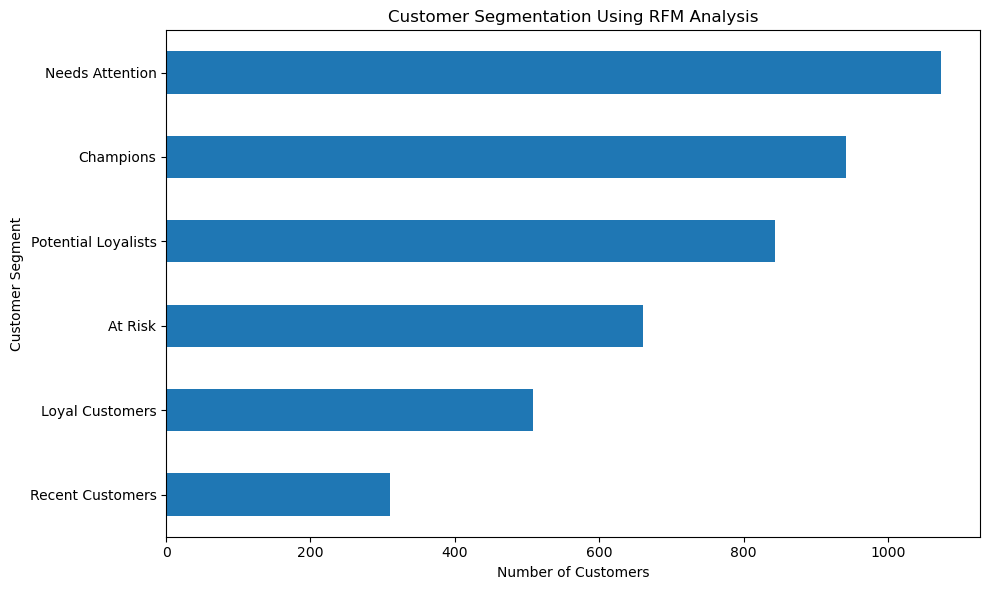

In [12]:
# Import the plotting library
import matplotlib.pyplot as plt

# Count customers in each segment and sort the results
segment_counts = rfm["Segment"].value_counts().sort_values(ascending=True)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))
segment_counts.plot(kind="barh")

# Add a title and axis labels
plt.title("Customer Segmentation Using RFM Analysis")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")

# Display the chart neatly
plt.tight_layout()
plt.show()

Revenue by Customer Segment (£):


,Segment,Monetary
0,Champions,5737952.120
1,Loyal Customers,927623.751
2,At Risk,823912.441
3,Potential Loyalists,731677.860
4,Needs Attention,523803.282
5,Recent Customers,142239.440


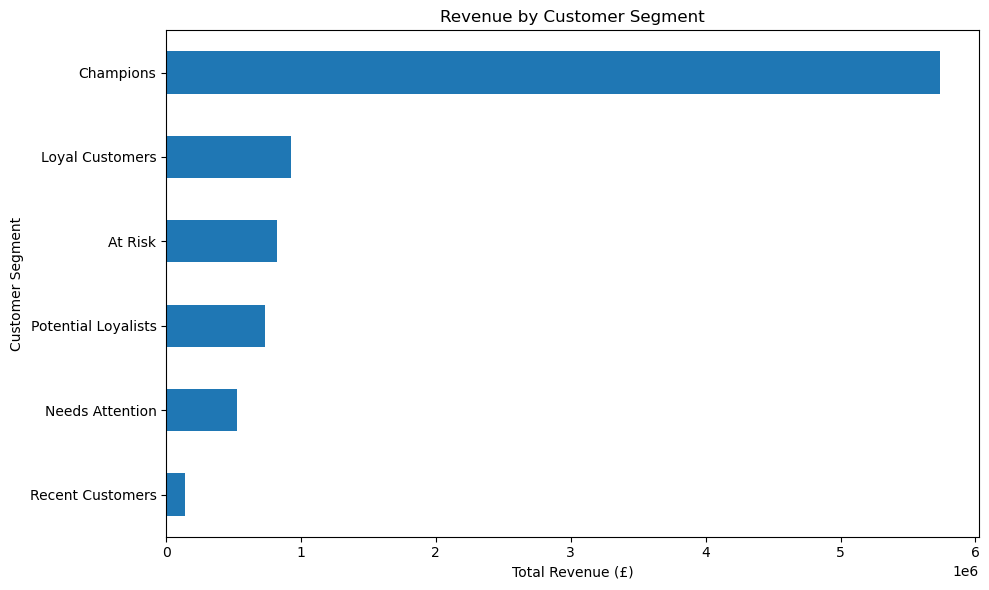

In [13]:
# Calculate total revenue for each customer segment
segment_revenue = rfm.groupby("Segment")["Monetary"].sum().sort_values(
    ascending=False
)

# Display revenue generated by each segment
print("Revenue by Customer Segment (£):")
display(segment_revenue.reset_index())

# Import the plotting library
import matplotlib.pyplot as plt

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))
segment_revenue.sort_values().plot(kind="barh")

# Add the chart title and axis labels
plt.title("Revenue by Customer Segment")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Customer Segment")

# Display the chart
plt.tight_layout()
plt.show()

In [14]:
# Count customers in each segment
segment_summary = rfm.groupby("Segment").agg(
    Customer_Count=("CustomerID", "count"),
    Total_Revenue=("Monetary", "sum")
).reset_index()

# Calculate the percentage of all customers in each segment
segment_summary["Customer_Percentage"] = (
    segment_summary["Customer_Count"] / len(rfm) * 100
).round(2)

# Sort segments by total revenue, from highest to lowest
segment_summary = segment_summary.sort_values(
    by="Total_Revenue", ascending=False
)

# Display the summary table
display(segment_summary)

,Segment,Customer_Count,Total_Revenue,Customer_Percentage
1,Champions,942,5737952.120,21.72
2,Loyal Customers,508,927623.751,11.71
0,At Risk,661,823912.441,15.24
4,Potential Loyalists,843,731677.860,19.43
3,Needs Attention,1074,523803.282,24.76
5,Recent Customers,310,142239.440,7.15


## Business Recommendations

Based on the RFM analysis, the following recommendations can help improve customer retention and revenue:

1. **Champions:** This segment generates the highest revenue (£5.74 million). The business should reward these customers with loyalty benefits, exclusive offers, and personalized recommendations.

2. **Loyal Customers:** Offer loyalty points, membership benefits, and special discounts to encourage repeat purchases and strengthen long-term relationships.

3. **At Risk:** These customers may become inactive. The business should use personalized emails, reminder messages, and limited-time offers to encourage them to return.

4. **Potential Loyalists:** Encourage these customers to purchase more frequently through product recommendations, introductory loyalty rewards, and relevant offers.

5. **Needs Attention:** This is the largest segment, representing 24.76% of customers. The business should test targeted campaigns to understand their needs and encourage repeat purchases.

6. **Recent Customers:** Build relationships with these customers through welcome messages, product suggestions, and follow-up offers that encourage a second purchase.

## Key Finding

Champions account for approximately 21.72% of customers but generate the majority of the revenue, at around £5.74 million. Meanwhile, Needs Attention is the largest customer segment, with 1,074 customers. The business should retain its high-value customers while developing targeted strategies to improve engagement among less active customers.

## Conclusion

This project used Python and RFM analysis to study customer purchasing behaviour in the Online Retail dataset. The analysis included data cleaning, exploratory data analysis, revenue trends, product and country analysis, and customer segmentation.

The results identified six customer segments with different purchasing patterns and revenue contributions. Champions generated the highest revenue, while Needs Attention represented the largest share of customers. These findings can help the business make better marketing decisions, improve customer retention, and develop targeted promotional strategies.

Overall, RFM analysis provides a practical way to understand customer value and support data-driven retail business decisions.